In [2]:
import numpy as np

In [3]:
A = [12, 13, 14, 15]
B = np.array(A, dtype = np.uint8)
C = np.unpackbits(B)
print(B)
print(C)

[12 13 14 15]
[0 0 0 0 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 0 0 0 0 1 1 1 1]


# In this notebook my goal is to use different Deep Learning models on X-Ray Images for detecting Pneumonia in the chest of different patients

In [4]:
!pip install deepinv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.0 MB/s  0:00:00


In [5]:
import torch
import glob
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
# Evaluation & Metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
import deepinv
from pathlib import Path
%matplotlib inline

In [6]:
import os
import zipfile
import requests

# Updated direct download link for ChestXRay2017.zip
url = "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
zip_path = "ChestXRay2017.zip"
extract_dir = "./data"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

print("Downloading dataset from direct Mendeley link...")
response = requests.get(url, headers=headers, stream=True, allow_redirects=True)
response.raise_for_status()

# Save binary stream in 8MB chunks
with open(zip_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
        if chunk:
            f.write(chunk)

file_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Download finished! File size: {file_size_mb:.2f} MB")

print("Extracting zip and skipping __MACOSX metadata...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for member in zip_ref.infolist():
        if not member.filename.startswith('__MACOSX/') and not member.filename.startswith('.'):
            zip_ref.extract(member, extract_dir)

os.remove(zip_path)
print("Extraction complete. Archive cleaned up.")

Download finished! File size: 1178.28 MB
Extracting zip and skipping __MACOSX metadata...
Extraction complete. Archive cleaned up.


Found 1349 Normal X-rays
Found 3883 Pneumonia X-rays



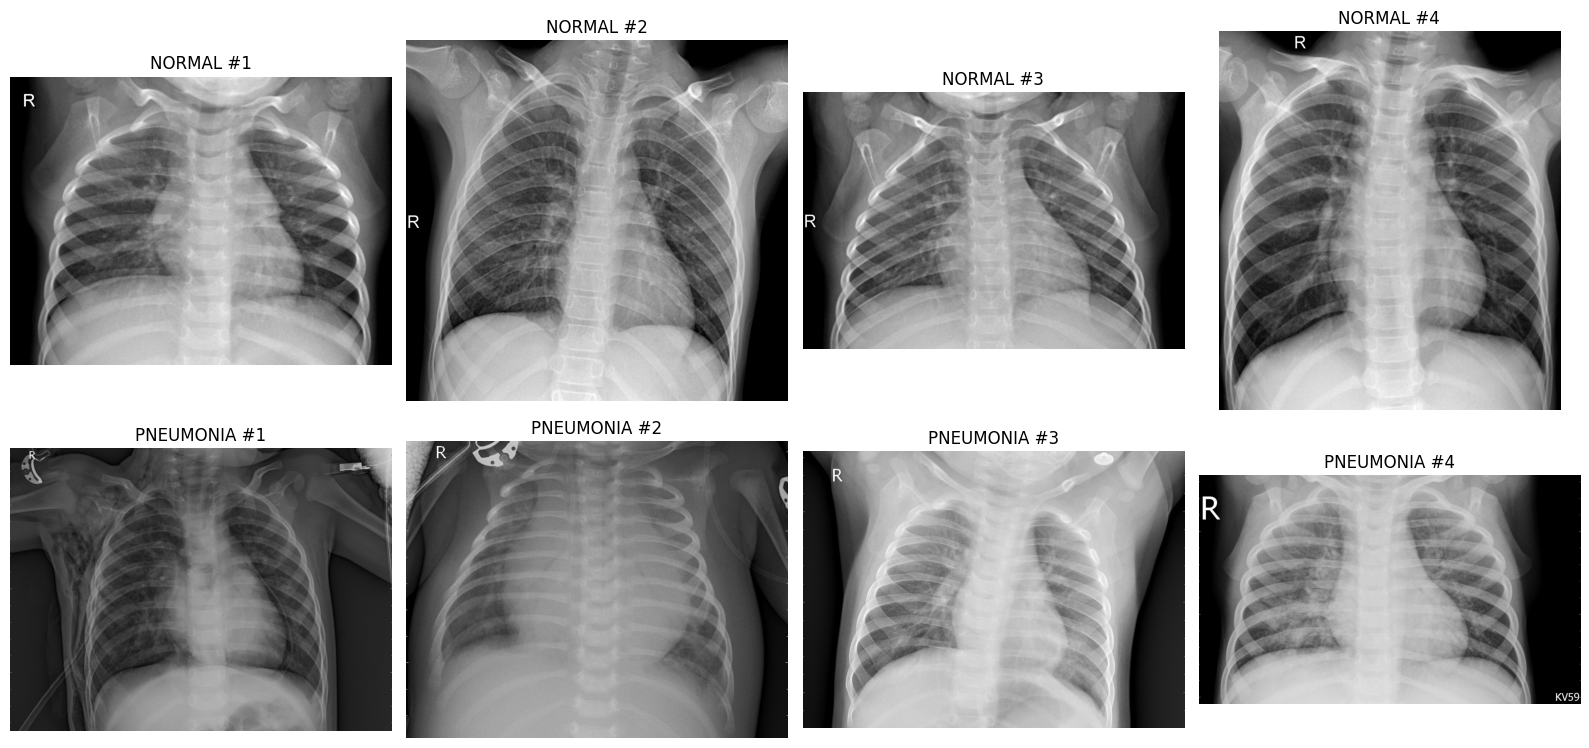

In [7]:
# 1. Path to the extracted dataset
data_dir = "./data/chest_xray" if os.path.exists("./data/chest_xray") else "./chest_xray"

# 2. Grab file paths for both classes
normal_files = glob.glob(os.path.join(data_dir, "train/NORMAL/*.jpeg"))
pneumonia_files = glob.glob(os.path.join(data_dir, "train/PNEUMONIA/*.jpeg"))

print(f"Found {len(normal_files)} Normal X-rays")
print(f"Found {len(pneumonia_files)} Pneumonia X-rays\n")

# 3. Plot sample images (4 Normal, 4 Pneumonia)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    # Display Normal X-Rays
    img_normal = Image.open(normal_files[i])
    axes[0, i].imshow(img_normal, cmap='gray')
    axes[0, i].set_title(f"NORMAL #{i+1}")
    axes[0, i].axis('off')
    
    # Display Pneumonia X-Rays
    img_pneumonia = Image.open(pneumonia_files[i])
    axes[1, i].imshow(img_pneumonia, cmap='gray')
    axes[1, i].set_title(f"PNEUMONIA #{i+1}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [8]:
import torch

print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")

CUDA Available: True
Device Name: Tesla T4
CUDA Version: 13.0


In [20]:
from torchvision import datasets, transforms

device = "cuda"
batch_size = 32
image_size = 32

transform = transforms.Compose(
    [
        transforms.Resize((image_size, image_size)),
        transforms.Grayscale(num_output_channels=1),
        transforms.ToTensor(),
        transforms.Normalize((0.0,), (1.0,)),
    ]
)

full_dataset = datasets.ImageFolder(
    root="/kaggle/working/data/chest_xray/train", transform=transform
)

normal_idx = full_dataset.class_to_idx["NORMAL"]

normal_indices = [i for i, (_, label) in enumerate(full_dataset.samples) if label == normal_idx]
dataset = torch.utils.data.Subset(full_dataset, normal_indices)

train_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

lr = 1e-4
epochs = 100

model = deepinv.models.DiffUNet(in_channels=1, out_channels=1, pretrained=None).to(
    device
)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
mse = deepinv.loss.MSE()

beta_start = 1e-4
beta_end = 0.02
timesteps = 1000

betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

loss_over_time = []

for epoch in range(epochs):
    model.train()
    running_loss = 0
    for data, _ in train_loader:
        imgs = data.to(device)
        noise = torch.randn_like(imgs)
        t = torch.randint(0, timesteps, (imgs.size(0),), device=device)

        noised_imgs = (
            sqrt_alphas_cumprod[t, None, None, None] * imgs
            + sqrt_one_minus_alphas_cumprod[t, None, None, None] * noise
        )

        optimizer.zero_grad()
        estimated_noise = model(noised_imgs, t, type_t="timestep")
        loss = mse(estimated_noise, noise).mean()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_over_time.append(epoch_loss)
    print(f"Epoch [{epoch + 1}/{epochs}] - Loss: {epoch_loss:.6f}")

torch.save(
    model.state_dict(),
    "trained_diffusion_model.pth",
)

Epoch [1/100] - Loss: 0.433926
Epoch [2/100] - Loss: 0.041215
Epoch [3/100] - Loss: 0.027084
Epoch [4/100] - Loss: 0.024394
Epoch [5/100] - Loss: 0.020896
Epoch [6/100] - Loss: 0.022116
Epoch [7/100] - Loss: 0.019774
Epoch [8/100] - Loss: 0.022280
Epoch [9/100] - Loss: 0.022313
Epoch [10/100] - Loss: 0.020140
Epoch [11/100] - Loss: 0.020655
Epoch [12/100] - Loss: 0.019279
Epoch [13/100] - Loss: 0.019568
Epoch [14/100] - Loss: 0.017901
Epoch [15/100] - Loss: 0.017965
Epoch [16/100] - Loss: 0.019341
Epoch [17/100] - Loss: 0.016162
Epoch [18/100] - Loss: 0.017937
Epoch [19/100] - Loss: 0.016688
Epoch [20/100] - Loss: 0.018371
Epoch [21/100] - Loss: 0.020572
Epoch [22/100] - Loss: 0.017686
Epoch [23/100] - Loss: 0.017432
Epoch [24/100] - Loss: 0.014690
Epoch [25/100] - Loss: 0.020859
Epoch [26/100] - Loss: 0.018550
Epoch [27/100] - Loss: 0.018500
Epoch [28/100] - Loss: 0.017017
Epoch [29/100] - Loss: 0.017482
Epoch [30/100] - Loss: 0.019203
Epoch [31/100] - Loss: 0.014193
Epoch [32/100] - 

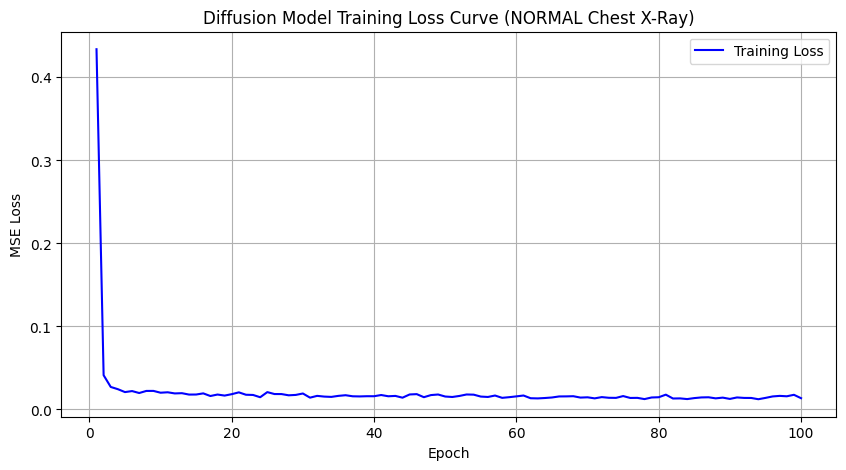

In [21]:
# Plot the training loss curve
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), loss_over_time, label="Training Loss", color="blue")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Diffusion Model Training Loss Curve (NORMAL Chest X-Ray)")
plt.grid(True)
plt.legend()
plt.show()

In [30]:
from pathlib import Path
from torchvision.utils import save_image

device = "cuda" if torch.cuda.is_available() else "cpu"
image_size = 32
checkpoint_path = "/kaggle/working/trained_diffusion_model.pth"

# 1. Initialize UNet and load trained weights using Path object
model = deepinv.models.DiffUNet(
    in_channels=1, out_channels=1, pretrained=None
).to(device)

# 2. Load the state dict manually with strict=False to bypass unexpected buffer keys
state_dict = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(state_dict, strict=False)

model

DiffUNet(
  (time_embed): Sequential(
    (0): Linear(in_features=128, out_features=512, bias=True)
    (1): SiLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
  )
  (input_blocks): ModuleList(
    (0): TimestepEmbedSequential(
      (0): Conv2d(1, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (1): TimestepEmbedSequential(
      (0): ResBlock(
        (in_layers): Sequential(
          (0): GroupNorm32(32, 128, eps=1e-05, affine=True)
          (1): SiLU()
          (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (h_upd): Identity()
        (x_upd): Identity()
        (emb_layers): Sequential(
          (0): SiLU()
          (1): Linear(in_features=512, out_features=256, bias=True)
        )
        (out_layers): Sequential(
          (0): GroupNorm32(32, 128, eps=1e-05, affine=True)
          (1): SiLU()
          (2): Dropout(p=0.1, inplace=False)
          (3): Conv2d(128, 128, kernel_size=(3, 3), strid

In [33]:
# 2. Set noise schedule
beta_start = 1e-4
beta_end = 0.02
timesteps = 1000

betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

model.eval()

n_samples = 32
# print(model.eval())

In [34]:
# 3. Sampling loop (Reverse Diffusion)
with torch.no_grad():
    x = torch.randn(n_samples, 1, image_size, image_size).to(device)

    for t in reversed(range(timesteps)):
        t_tensor = torch.ones(n_samples, device=device).long() * t

        predicted_noise = model(x, t_tensor, type_t="timestep")

        alpha = alphas[t]
        alpha_cumprod = alphas_cumprod[t]
        beta = betas[t]

        if t > 0:
            noise = torch.randn_like(x)
        else:
            noise = 0

        x = (1 / torch.sqrt(alpha)) * (
            x - (beta / torch.sqrt(1 - alpha_cumprod)) * predicted_noise
        ) + torch.sqrt(beta) * noise

In [35]:
# 4. Post-process (clamp pixel values to standard [0, 1] visual range)
x = torch.clamp(x, 0.0, 1.0)

# 5. Save generated batch as a single grid image
save_image(x, "generated_normal_xrays.png", nrow=8)

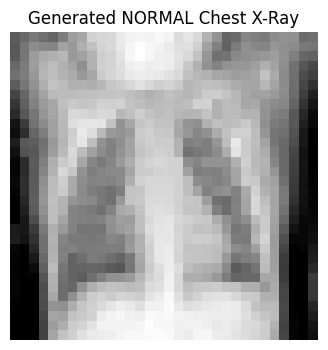

In [36]:
# 6. Display the first generated X-ray sample inline
plt.figure(figsize=(4, 4))
plt.imshow(x[0].squeeze().cpu().numpy(), cmap="gray")
plt.title("Generated NORMAL Chest X-Ray")
plt.axis("off")
plt.show()

### Let's test on our test data:
* You compare each test image $X$ with its own reconstruction $X'$.
* You don’t add full noise. You run the forward process only up to some partial timestep $t$ and then denoise back from there:
* * $t$ too small: most of the image survives the noising, so the model just copies it back, pneumonia included. The error stays low for sick patients too.
* * $t$ too large: the patient’s own anatomy is wiped out, so the model draws a generic healthy lung. The error is high for everyone because of anatomy, not disease. 

In [51]:
from sklearn.metrics import roc_auc_score
from torchvision.transforms.functional import gaussian_blur
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
image_size = 32
TRAIN_RANGE = "01"
T_EVALS = [100, 200, 300]
N_SAMPLES = 1
FULL_CHAIN = True
BLUR_SIGMA = 1.5
CROP = 2
MODEL_PATH = "/kaggle/working/trained_diffusion_model.pth"
TEST_ROOT = "/kaggle/working/data/chest_xray/test"

In [52]:
tf = [transforms.Resize((image_size, image_size)),
      transforms.Grayscale(num_output_channels=1),
      transforms.ToTensor()]
if TRAIN_RANGE == "-11":
    tf.append(transforms.Normalize((0.5,), (0.5,)))
lo, hi = (0.0, 1.0) if TRAIN_RANGE == "01" else (-1.0, 1.0)

test_dataset = datasets.ImageFolder(root=TEST_ROOT, transform=transforms.Compose(tf))
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)
pneu_idx = test_dataset.class_to_idx["PNEUMONIA"]

In [53]:
model = deepinv.models.DiffUNet(in_channels=1, out_channels=1, pretrained=None).to(device)
state = torch.load(MODEL_PATH, map_location=device)
state = {k.removeprefix("module."): v for k, v in state.items()}
model.load_state_dict(state, strict=True) 
model.eval()

DiffUNet(
  (time_embed): Sequential(
    (0): Linear(in_features=128, out_features=512, bias=True)
    (1): SiLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
  )
  (input_blocks): ModuleList(
    (0): TimestepEmbedSequential(
      (0): Conv2d(1, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (1): TimestepEmbedSequential(
      (0): ResBlock(
        (in_layers): Sequential(
          (0): GroupNorm32(32, 128, eps=1e-05, affine=True)
          (1): SiLU()
          (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (h_upd): Identity()
        (x_upd): Identity()
        (emb_layers): Sequential(
          (0): SiLU()
          (1): Linear(in_features=512, out_features=256, bias=True)
        )
        (out_layers): Sequential(
          (0): GroupNorm32(32, 128, eps=1e-05, affine=True)
          (1): SiLU()
          (2): Dropout(p=0.1, inplace=False)
          (3): Conv2d(128, 128, kernel_size=(3, 3), strid

In [54]:
# schedule (must match training)
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)
alphas = 1.0 - betas
ac = torch.cumprod(alphas, dim=0)

def predict_eps(x_t, t_vec):
    out = model(x_t, t_vec, type_t="timestep")
    assert out.shape == x_t.shape, f"model output {out.shape} != input {x_t.shape}"
    return out

@torch.no_grad()
def reconstruct(x0, t):
    B = x0.shape[0]
    eps = torch.randn_like(x0)
    x_t = ac[t].sqrt() * x0 + (1 - ac[t]).sqrt() * eps
    t_vec = torch.full((B,), t, device=device, dtype=torch.long)
    eps_hat = predict_eps(x_t, t_vec)

    eps_score = ((eps_hat - eps) ** 2).mean(dim=(1, 2, 3))  # old score, kept for comparison

    if not FULL_CHAIN:
        x0_hat = (x_t - (1 - ac[t]).sqrt() * eps_hat) / ac[t].sqrt()
    else:
        x = x_t
        for s in range(t, -1, -1):
            s_vec = torch.full((B,), s, device=device, dtype=torch.long)
            e = eps_hat if s == t else predict_eps(x, s_vec)
            mean = (x - betas[s] / (1 - ac[s]).sqrt() * e) / alphas[s].sqrt()
            if s > 0:
                var = betas[s] * (1 - ac[s - 1]) / (1 - ac[s])
                x = mean + var.sqrt() * torch.randn_like(x)
            else:
                x = mean
        x0_hat = x

    x0_hat = x0_hat.clamp(lo, hi)
    return eps_score, (x0 - x0_hat).abs(), x0_hat

In [55]:
eps_scores, mean_scores, q95_scores, labels = [], [], [], []
examples = {0: [], 1: []}  # up to 3 (img, recon, map) per class

for img, lab in test_loader:
    img = img.to(device)
    eps_acc = torch.zeros(img.shape[0], device=device)
    map_acc = torch.zeros_like(img)
    rec_last = None
    for t in T_EVALS:
        for _ in range(N_SAMPLES):
            e, m, rec_last = reconstruct(img, t)
            eps_acc += e
            map_acc += m
    n = len(T_EVALS) * N_SAMPLES
    eps_acc /= n
    map_acc /= n

    # flat = map_acc.flatten(1)
    map_acc = gaussian_blur(map_acc, kernel_size=5, sigma=BLUR_SIGMA)
    map_acc = map_acc[..., CROP:-CROP, CROP:-CROP]
    flat = map_acc.flatten(1)
    eps_scores.append(eps_acc.cpu())
    mean_scores.append(flat.mean(1).cpu())
    q95_scores.append(flat.quantile(0.95, dim=1).cpu())
    y = (lab == pneu_idx).long()
    labels.append(y)

    for i in range(img.shape[0]):
        c = y[i].item()
        if len(examples[c]) < 3:
            examples[c].append((img[i, 0].cpu(), rec_last[i, 0].cpu(), map_acc[i, 0].cpu()))

eps_scores  = torch.cat(eps_scores).numpy()
mean_scores = torch.cat(mean_scores).numpy()
q95_scores  = torch.cat(q95_scores).numpy()
labels = torch.cat(labels).numpy()

noise-pred MSE        normal=0.01942  pneumonia=0.02298  AUROC=0.6543
recon |X-X'| mean     normal=0.08252  pneumonia=0.08861  AUROC=0.6375
recon |X-X'| q95      normal=0.14145  pneumonia=0.15626  AUROC=0.6545


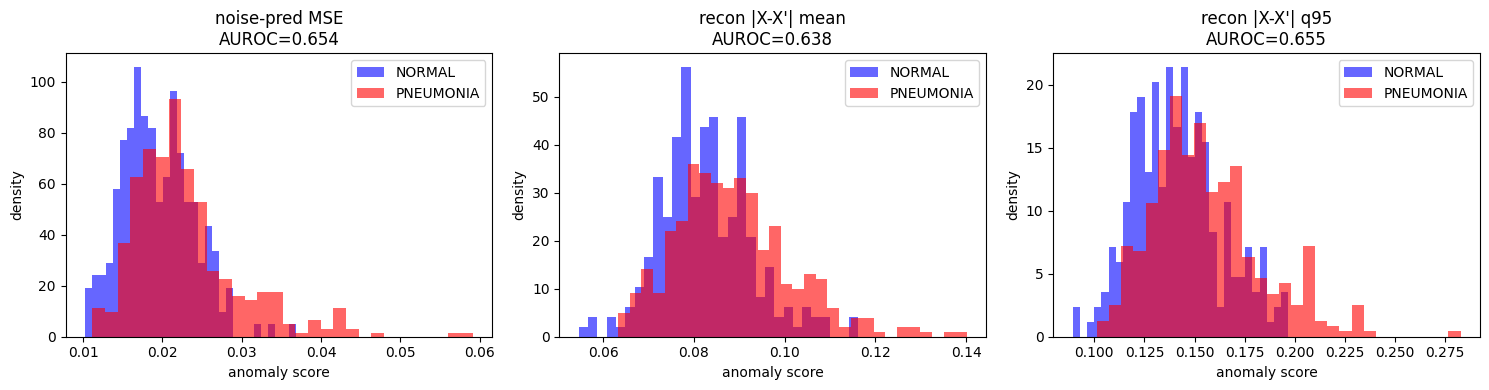

In [56]:
# evaluation part
scores = {"noise-pred MSE": eps_scores, "recon |X-X'| mean": mean_scores, "recon |X-X'| q95": q95_scores}
for name, s in scores.items():
    print(f"{name:20s}  normal={s[labels==0].mean():.5f}  pneumonia={s[labels==1].mean():.5f}  "
          f"AUROC={roc_auc_score(labels, s):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, s) in zip(axes, scores.items()):
    ax.hist(s[labels == 0], bins=30, alpha=0.6, density=True, label="NORMAL", color="blue")
    ax.hist(s[labels == 1], bins=30, alpha=0.6, density=True, label="PNEUMONIA", color="red")
    ax.set_title(f"{name}\nAUROC={roc_auc_score(labels, s):.3f}")
    ax.set_xlabel("anomaly score"); ax.set_ylabel("density"); ax.legend()
plt.tight_layout(); plt.show()

Pneumonia fraction (precision baseline / AP baseline): 0.6250

== noise-pred MSE ==
  @ tau = 95th pct of normals (0.02673):
    TP=78  FP=12  FN=312  TN=222
    precision=0.8667  recall=0.2000  specificity=0.9487  F1=0.3250
  best-F1 threshold (0.01397): precision=0.6447  recall=0.9769  F1=0.7768
  AP=0.7677  (baseline 0.6250)

== recon |X-X'| mean ==
  @ tau = 95th pct of normals (0.09996):
    TP=66  FP=12  FN=324  TN=222
    precision=0.8462  recall=0.1692  specificity=0.9487  F1=0.2821
  best-F1 threshold (0.06329): precision=0.6311  recall=1.0000  F1=0.7738
  AP=0.7546  (baseline 0.6250)

== recon |X-X'| q95 ==
  @ tau = 95th pct of normals (0.18196):
    TP=63  FP=12  FN=327  TN=222
    precision=0.8400  recall=0.1615  specificity=0.9487  F1=0.2710
  best-F1 threshold (0.11091): precision=0.6370  recall=0.9897  F1=0.7751
  AP=0.7654  (baseline 0.6250)



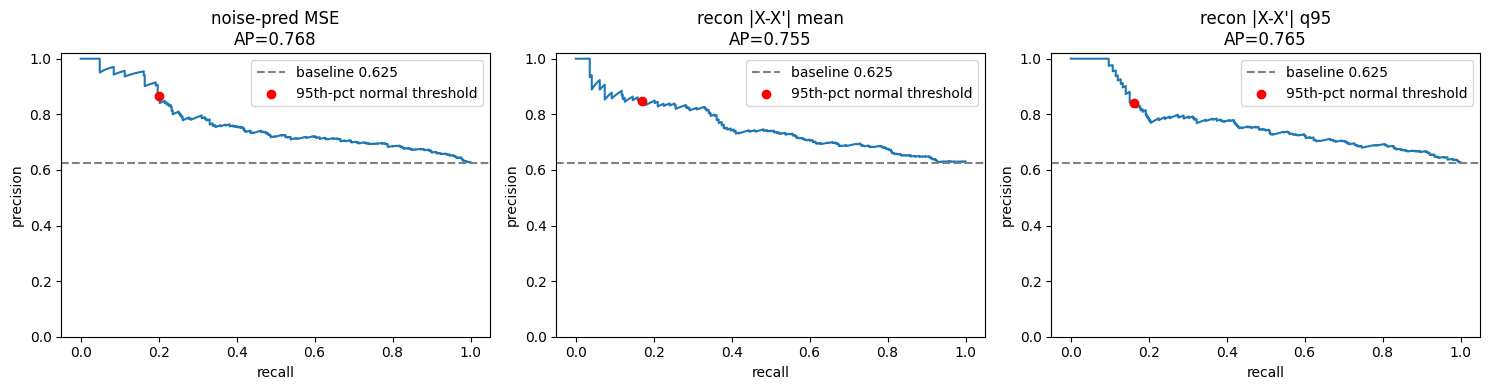

In [59]:
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             average_precision_score, precision_recall_curve)

baseline = labels.mean()  # precision of "flag everything" = pneumonia fraction
print(f"Pneumonia fraction (precision baseline / AP baseline): {baseline:.4f}\n")

fig, axes = plt.subplots(1, len(scores), figsize=(5 * len(scores), 4))

for ax, (name, s) in zip(axes, scores.items()):
    # threshold: 95th percentile of NORMAL scores -> ~5% of healthy images flagged
    tau = np.quantile(s[labels == 0], 0.95)
    pred = (s > tau).astype(int)

    tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
    prec = precision_score(labels, pred, zero_division=0)
    rec  = recall_score(labels, pred)
    spec = tn / (tn + fp)
    f1   = f1_score(labels, pred)
    ap   = average_precision_score(labels, s)

    # threshold-free PR curve + best-F1 point (optimistic: chosen on test set)
    p_curve, r_curve, thr = precision_recall_curve(labels, s)
    f1_curve = 2 * p_curve[:-1] * r_curve[:-1] / (p_curve[:-1] + r_curve[:-1] + 1e-12)
    best = f1_curve.argmax()

    print(f"== {name} ==")
    print(f"  @ tau = 95th pct of normals ({tau:.5f}):")
    print(f"    TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    print(f"    precision={prec:.4f}  recall={rec:.4f}  specificity={spec:.4f}  F1={f1:.4f}")
    print(f"  best-F1 threshold ({thr[best]:.5f}): precision={p_curve[best]:.4f}  "
          f"recall={r_curve[best]:.4f}  F1={f1_curve[best]:.4f}")
    print(f"  AP={ap:.4f}  (baseline {baseline:.4f})\n")

    ax.plot(r_curve, p_curve)
    ax.axhline(baseline, ls="--", color="gray", label=f"baseline {baseline:.3f}")
    ax.scatter([rec], [prec], color="red", zorder=3, label="95th-pct normal threshold")
    ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.set_title(f"{name}\nAP={ap:.3f}")
    ax.set_ylim(0, 1.02); ax.legend()

plt.tight_layout(); plt.show()

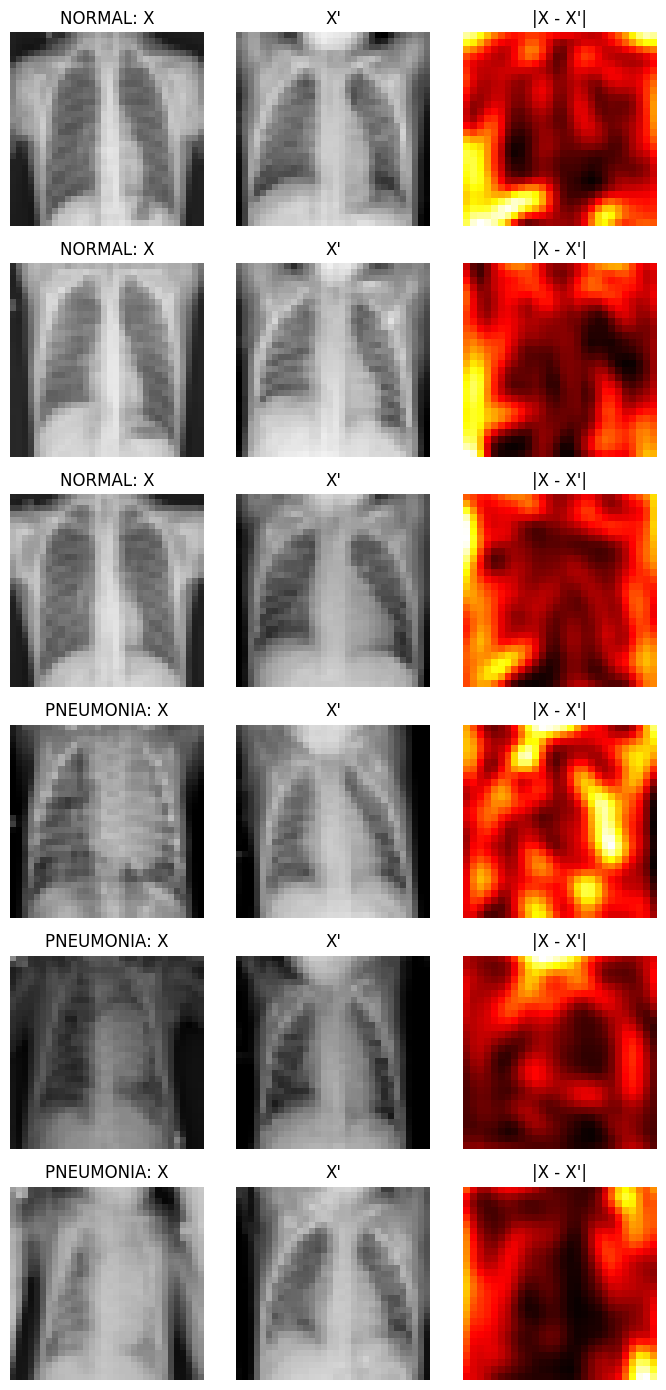

In [58]:
# heatmaps
fig, axes = plt.subplots(6, 3, figsize=(7, 14))
row = 0
for c, cname in [(0, "NORMAL"), (1, "PNEUMONIA")]:
    for x, r, m in examples[c]:
        axes[row, 0].imshow(x, cmap="gray", vmin=lo, vmax=hi); axes[row, 0].set_title(f"{cname}: X")
        axes[row, 1].imshow(r, cmap="gray", vmin=lo, vmax=hi); axes[row, 1].set_title("X'")
        axes[row, 2].imshow(m, cmap="hot");                    axes[row, 2].set_title("|X - X'|")
        row += 1
for a in axes.flat:
    a.axis("off")
plt.tight_layout(); plt.show()